# 5-08 종목정보 불러오기 — 상장사 목록·식별자·기업 개요·52주 주가

**질문 예시:** "상장사 전체 목록이랑 업종·결산월 뽑아줘", "내 관심종목 기업 개요랑 52주 고저 보여줘"

뉴스·공시를 상장사 기준으로 거르거나 종목별로 묶으려면 먼저 **상장사 목록**이 있어야 합니다.
`GetStockSymbols()` 한 번이면 4,400여 종목의 시장·업종·식별자(NICE 코드, 사업자번호, 법인번호)·결산월·기업집단이 옵니다.
종목별로 `GetEntitySummary`를 반복해 부를 필요가 없습니다.

[![Colab에서 열기](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beaten-by-the-market/deepsearch/blob/main/scenarios/5_data_lookup/08_stock_info.ipynb)

## 0. 준비
Colab 왼쪽 🔑(Secrets)에 `DEEPSEARCH_API_KEY`를 등록하고 이 노트북의 액세스를 켠 뒤 아래 두 셀을 실행하세요. 두 번째 셀은 모든 시나리오에 공통인 헬퍼입니다(접어 두어도 됩니다).

In [1]:
# Colab에서만: 한글 차트 폰트 설치 (로컬에서는 건너뜀)
import sys
if "google.colab" in sys.modules:
    !pip -q install koreanize-matplotlib

In [2]:
# ── DeepSearch 헬퍼 (모든 시나리오 노트북 공통) ─────────────────────────────
# Colab: 왼쪽 🔑(Secrets)에 이름 DEEPSEARCH_API_KEY 로 키를 넣고 "노트북 액세스"를 켜세요.
#        키는 "아이디:비밀번호" 형식이든 base64 문자열이든 됩니다. 키 값은 출력하지 않습니다.
# 로컬: 환경변수 DEEPSEARCH_API_KEY / API_KEY 또는 상위 폴더의 .env 를 읽습니다.
import base64, json, os, sys, time
from datetime import date, datetime, timedelta

import pandas as pd
import requests

IN_COLAB = "google.colab" in sys.modules
API_URL = "https://api.deepsearch.com/v1/compute"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)


def _norm_key(k):
    k = k.strip().strip('"').strip("'")
    return base64.b64encode(k.encode()).decode() if ":" in k else k


def _find_key():
    if IN_COLAB:
        try:
            from google.colab import userdata
            k = userdata.get("DEEPSEARCH_API_KEY")
            if k:
                return _norm_key(k)
        except Exception:
            pass
    for name in ("DEEPSEARCH_API_KEY", "API_KEY"):
        if os.environ.get(name):
            return _norm_key(os.environ[name])
    d = os.path.abspath(os.getcwd())
    while True:
        p = os.path.join(d, ".env")
        if os.path.isfile(p):
            for line in open(p, encoding="utf-8-sig"):
                if "=" in line and not line.strip().startswith("#"):
                    k, v = line.split("=", 1)
                    if k.strip() in ("DEEPSEARCH_API_KEY", "API_KEY") and v.strip():
                        return _norm_key(v)
        if os.path.dirname(d) == d:
            break
        d = os.path.dirname(d)
    from getpass import getpass
    return _norm_key(getpass("DeepSearch API 키: "))


_KEY = _find_key()


class DSError(Exception):
    pass


def ds(query, timeout=180, retries=3):
    """compute 호출 → 응답 JSON. 서버가 돌려준 오류(data.exceptions)는 DSError."""
    last = None
    for i in range(retries):
        try:
            r = requests.post(API_URL, json={"input": query}, timeout=timeout,
                              headers={"Authorization": "Basic " + _KEY})
            body = r.json()
        except Exception as e:  # 네트워크·일시 오류만 재시도
            last = e
            time.sleep(3 * (i + 1))
            continue
        exc = (body.get("data") or {}).get("exceptions") or []
        if exc or r.status_code >= 400:
            msg = "; ".join(f"{x.get('class', '')}: {' '.join(map(str, x.get('args') or [x.get('message', '')]))}"
                            if isinstance(x, dict) else str(x) for x in exc)
            raise DSError(f"{r.status_code} {msg or body}"[:500])
        return body
    raise DSError(f"요청 실패: {last}")


def _pod(body):
    pods = (body.get("data") or {}).get("pods") or []
    return pods[1] if len(pods) >= 2 else {}


def ds_df(query, **kw):
    """DataFrame 결과(재무·시세·경제지표 등) → pandas DataFrame. 결과가 없으면 빈 DataFrame."""
    c = _pod(ds(query, **kw)).get("content") or {}
    data = c.get("data") if isinstance(c, dict) else None
    if not isinstance(data, dict) or not data:
        return pd.DataFrame()
    cols = [x for x in (c.get("columns") or data.keys()) if x in data]
    df = pd.DataFrame({x: data[x] for x in cols})
    for x in ("date", "created_at"):
        if x in df and df[x].dtype == object:
            df[x] = pd.to_datetime(df[x].astype(str).str[:19], errors="coerce")
    return df


def _polarity(x):
    """문서 긍부정: polarity.name, 없으면 customized_ml.kis 모델 값(최근 뉴스는 절반가량이 이쪽에만 있음)."""
    p = x.get("polarity")
    if isinstance(p, dict) and p.get("name"):
        return p["name"]
    k = (((x.get("customized_ml") or {}).get("kis") or {}).get("ip_multitask") or {}).get("polarity") or {}
    return k.get("name")


def doc_search(category, section, query, date_from, date_to, count=100, pages=1):
    """DocumentSearch → (총건수, 문서 DataFrame). category: news/research/company/patent. 기간은 1년 이내.
    종목 지정은 securities.symbol:005930 (접두어 없는 6자리)이 뉴스·리서치·공시 모두에서 가장 정확합니다.
    securities.symbol:KRX:005930 은 키워드 검색으로 바뀌어 건수가 줄고, securities.name: 은 리서치(공식명
    '에스케이하이닉스')·공시(DART명 '현대자동차')에서 놓칩니다(2026-11-25 확인). 여러 종목: securities.symbol:(005930 or 000660)"""
    rows, total = [], 0
    for page in range(1, pages + 1):
        q = (f'DocumentSearch(["{category}"],{json.dumps(section, ensure_ascii=False)},'
             f'{json.dumps(query, ensure_ascii=False)},count={count},page={page},'
             f'date_from={date_from},date_to={date_to})')
        c = _pod(ds(q)).get("content") or {}
        d = c.get("data") if isinstance(c.get("data"), dict) else c
        total = d.get("total_matches") or 0
        docs = d.get("docs") or []
        for x in docs:
            secs = x.get("securities") or []
            rows.append({
                "created_at": pd.to_datetime(str(x.get("created_at"))[:19], errors="coerce"),
                "publisher": x.get("publisher"),
                "title": " ".join(str(x.get("title") or "").split()),
                "stocks": ", ".join(s.get("name", "") for s in secs),
                "symbols": ", ".join(s.get("symbol", "") for s in secs),
                "polarity": _polarity(x),
                "url": x.get("content_url"),
            })
        if len(docs) < count:
            break
    cols = ["created_at", "publisher", "title", "stocks", "symbols", "polarity", "url"]
    return total, pd.DataFrame(rows, columns=cols)


def doc_trends(category, section, query, date_from, date_to, interval="1d"):
    """DocumentTrends → DataFrame(date, count)."""
    q = (f'DocumentTrends(["{category}"],{json.dumps(section, ensure_ascii=False)},'
         f'{json.dumps(query, ensure_ascii=False)},interval="{interval}",'
         f'date_from={date_from},date_to={date_to})')
    c = _pod(ds(q)).get("content") or {}
    d = c.get("data") if isinstance(c.get("data"), dict) else c
    trends = d.get("trends") or []
    b = trends[0].get("buckets", []) if trends else []
    df = pd.DataFrame([{"date": x.get("key_as_string") or x.get("key"), "count": x.get("count", 0)} for x in b])
    if not df.empty:
        df["date"] = pd.to_datetime(df["date"].astype(str).str[:19], errors="coerce")
    return df


def stock_prices(entities, date_from, date_to, columns=None):
    """종목 목록의 일별 시세. entities 예: ["KRX:005930", "KRX:000660"] 또는 "KRX:005930".
    가격은 수정주가, 거래량·거래대금·시가총액은 당일 실제 값. change_rate 는 비율(0.01 = 1%)."""
    ents = [entities] if isinstance(entities, str) else list(entities)
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    q = (f'GetStockPrices([{", ".join(ents)}], columns={json.dumps(cols)}, '
         f'date_from={date_from}, date_to={date_to})')
    return ds_df(q)


_UNIVERSE = None


def universe():
    """현재 상장 종목 기본정보(GetStockSymbols 전 종목): symbol, name, market, industry_name 등.
    company_type_l1: 1 일반법인, 2 공기업(한국전력·기업은행 등 8종목), 8 ETF·ETN 등."""
    global _UNIVERSE
    if _UNIVERSE is None:
        u = ds_df("GetStockSymbols()")
        _UNIVERSE = u.rename(columns={"entity_name": "name"})[
            ["symbol", "name", "market", "company_type_l1", "industry_id", "industry_name", "date_listed",
             "fiscal_year_end", "conglomerate_id"]]
    return _UNIVERSE.copy()


def all_stocks(day, common_only=True, columns=None):
    """day(또는 그 이전 마지막 거래일)의 전 종목 하루치 시세 + 종목 정보. 한 번 호출로 4,000여 종목.
    common_only=True 이면 일반법인·공기업 보통주만(ETF·ETN·우선주 제외)."""
    day = pd.Timestamp(day).date()
    cols = columns or ["open", "high", "low", "close", "volume", "value", "change_rate", "market_cap"]
    snap = ds_df(f'GetStockPrices(columns={json.dumps(cols)}, '
                 f'date_from={day - timedelta(days=7)}, date_to={day})')
    df = snap.merge(universe().drop(columns=["date"], errors="ignore"), on="symbol", how="left")
    if common_only:
        df = df[df["company_type_l1"].isin(["1", "2"]) & df["symbol"].str.endswith("0")]
    df = df[df["market"].isin(["KOSPI", "KOSDAQ", "KONEX"])]
    if "change_rate" in df:
        df["change_pct"] = df["change_rate"] * 100
    return df.reset_index(drop=True)


def index_prices(date_from, date_to):
    """지수 11종(코스피·코스닥 계열) 일별. change_rate 는 퍼센트(1.94 = 1.94%).
    지수의 value(거래대금)는 백만원, volume(거래량)은 천주 단위로 보입니다(코스닥 2026-11-23 value 4,673,819 ≈ 4.7조)."""
    # 지수를 지정하지 않으면 최근 약 1,300행(≈118거래일)만 오고 앞 기간이 조용히 잘린다 → 140일씩 나눠 받는다
    start, end = pd.Timestamp(date_from), pd.Timestamp(date_to)
    parts = []
    while start <= end:
        stop = min(start + pd.Timedelta(days=139), end)
        parts.append(ds_df(f"GetMarketIndexes(date_from={start.date()}, date_to={stop.date()})"))
        start = stop + pd.Timedelta(days=1)
    df = pd.concat([x for x in parts if not x.empty], ignore_index=True) if parts else pd.DataFrame()
    return df.drop_duplicates(["date", "symbol"]).sort_values(["date", "symbol"]).reset_index(drop=True) if not df.empty else df


def fred(series, date_from, date_to):
    """FRED 시리즈 → 날짜 × 시리즈 넓은 표. 예: fred(["DGS10", "DEXKOUS"], "2026-10-01", "2026-11-24")"""
    ids = ", ".join(json.dumps(s) for s in series)
    df = ds_df(f"QueryFredSeriesData([{ids}], date_from={date_from}, date_to={date_to})")
    if df.empty:
        return df
    val = [c for c in df.columns if c not in ("entity_id", "date")][0]
    df["series"] = df["entity_id"].str.replace("FRED:", "", regex=False)
    wide = df.pivot_table(index="date", columns="series", values=val).sort_index()
    return wide[[s for s in series if s in wide.columns]]  # 요청한 순서대로


def krw(v, digits=1):
    """원 → '138.0조' / '5,027억'."""
    if v is None or pd.isna(v):
        return "-"
    a = abs(v)
    if a >= 1e12:
        return f"{v / 1e12:.{digits}f}조"
    if a >= 1e8:
        return f"{v / 1e8:,.0f}억"
    if a >= 1e4:
        return f"{v / 1e4:,.0f}만"
    return f"{v:,.0f}"


PRICE_NOTICE = ("※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). "
                "거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).")

# 한글 차트 폰트
import matplotlib.pyplot as plt
try:
    import koreanize_matplotlib  # noqa: F401  (Colab: 위 셀에서 설치)
except ImportError:
    if sys.platform.startswith("win"):
        plt.rcParams["font.family"] = "Malgun Gothic"
    elif sys.platform == "darwin":
        plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

print("DeepSearch 준비 완료", "(Colab)" if IN_COLAB else "(로컬)")

DeepSearch 준비 완료 (로컬)


In [3]:
ASOF = "2026-11-24"
# 관심종목: 종목명이나 6자리 코드 아무거나. Colab에서는 아래 UPLOAD=True 로 엑셀/CSV를 올려도 됩니다.
WATCHLIST = ["삼성전자", "000660", "에코프로비엠", "현대차", "NAVER", "한국전력"]
UPLOAD = False

## 1. 전 종목 기본정보
`company_type_l1`: 1 일반법인, 2 공기업(한국전력·기업은행 등), 8 ETF·ETN 등. 우선주는 종목코드 끝자리가 0이 아닙니다.

In [4]:
sym = ds_df("GetStockSymbols()")
sym["code"] = sym.symbol.str.replace("KRX:", "", regex=False)
sym["종류"] = sym.company_type_l1.map({"1": "일반법인", "2": "공기업", "8": "ETF·ETN 등"}).fillna("기타")
sym["우선주"] = ~sym.code.str.endswith("0")
print(f"전체 {len(sym):,}종목 (기준일 {sym.date.max().date()})")
print(pd.crosstab(sym.market, sym.종류, margins=True, margins_name="합계").to_string())
print("\n제공 컬럼:", ", ".join(sym.columns))

전체 4,442종목 (기준일 2026-11-24)
종류      ETF·ETN 등  공기업  일반법인    합계
market                            
KONEX           0    0   107   107
KOSDAQ          0    0  1837  1837
KOSPI        1563    8   927  2498
합계           1563    8  2871  4442

제공 컬럼: date, symbol, entity_name, exchange, market, symbol_nice, ceo, business_rid, company_rid, tel, fax, website, email, zipcode, address_land_lot, address_road_name, group_id, company_type_l1, company_type_l2, company_type_size, conglomerate_id, industry_id, industry_name, fs_type, fiscal_year_end, business_area, date_founded, date_listed, shares_outstanding, trading_halted, code, 종류, 우선주


일반법인·공기업 보통주만 남기면 "상장사"가 됩니다. 결산월과 기업집단 소속도 같이 볼 수 있습니다.

In [5]:
listed = sym[sym.company_type_l1.isin(["1", "2"]) & ~sym.우선주 & sym.market.isin(["KOSPI", "KOSDAQ", "KONEX"])].copy()
print(f"상장사(보통주) {len(listed):,}개:", listed.market.value_counts().to_dict())
print("결산월:", listed.fiscal_year_end.value_counts().head(5).to_dict())
print("기업집단 소속:", int(listed.conglomerate_id.notna().sum()), "개사")
listed[["code", "entity_name", "market", "industry_name", "symbol_nice", "business_rid", "company_rid",
        "fiscal_year_end", "date_listed"]].head(8)

상장사(보통주) 2,770개: {'KOSDAQ': 1835, 'KOSPI': 828, 'KONEX': 107}
결산월: {12: 2719, 3: 17, 6: 14, 11: 6, 9: 6}
기업집단 소속: 2125 개사


,code,entity_name,market,industry_name,symbol_nice,business_rid,company_rid,fiscal_year_end,date_listed
0,000020,동화약품,KOSPI,완제 의약품 제조업,NICE:350605,1108100102,1101110043870,12,1976-03-24T00:00:00
1,000040,다이나맥,KOSPI,모터사이클 제조업,NICE:320498,3058100020,1601110007032,12,1976-05-25T00:00:00
2,000050,경방,KOSPI,기타 대형 종합 소매업,NICE:320684,1078105232,1101110013287,12,1956-03-03T00:00:00
3,000070,삼양홀딩스,KOSPI,지주회사,NICE:320730,2088101320,1101110026181,12,1968-12-27T00:00:00
4,000080,하이트진로,KOSPI,알코올음료 제조업,NICE:310581,2148100777,1101110028591,12,2009-10-19T00:00:00
11,000100,유한양행,KOSPI,완제 의약품 제조업,NICE:350664,1188100601,1101110014409,12,1962-11-01T00:00:00
13,000120,CJ대한통운,KOSPI,도로 화물 운송업,NICE:710083,1108105034,1101110006167,12,1956-07-02T00:00:00
14,000140,하이트진로홀딩스,KOSPI,지주회사,NICE:310433,1078100955,1101110013766,12,1973-09-19T00:00:00


## 2. 종목 찾기 — 이름 일부나 코드로

In [6]:
def find_stock(text, only_listed=True):
    base = listed if only_listed else sym
    t = str(text).strip()
    hit = base[(base.code == t) | base.entity_name.str.contains(t, regex=False, na=False)]
    return hit[["code", "entity_name", "market", "industry_name"]]

find_stock("하이닉스")

,code,entity_name,market,industry_name
56,000660,SK하이닉스,KOSPI,"다이오드, 트랜지스터 및 유사 반도체소자 제조업"


In [7]:
find_stock("반도체", only_listed=True).head(3)   # 이름에 '반도체'가 든 종목 (업종 검색이 아님)

,code,entity_name,market,industry_name
1228,036540,SFA반도체,KOSDAQ,전자집적회로 제조업
1321,042700,한미반도체,KOSPI,반도체 제조용 기계 제조업
1360,046890,서울반도체,KOSDAQ,"다이오드, 트랜지스터 및 유사 반도체소자 제조업"


## 3. 관심종목 목록 만들기
이름이든 코드든 섞어 넣으면 코드로 바꿉니다. Colab에서 `UPLOAD = True`로 두면 파일 업로드 창이 뜹니다
(첫 열이나 `종목코드`·`종목명` 열을 읽습니다). 서식 파일은 아래 셀이 만들어 줍니다.

In [8]:
def to_codes(items):
    out, miss = [], []
    for it in items:
        it = str(it).strip().zfill(6) if str(it).strip().isdigit() else str(it).strip()
        hit = listed[(listed.code == it) | (listed.entity_name == it)]
        (out.append(hit.code.iloc[0]) if len(hit) else miss.append(it))
    if miss:
        print("찾지 못함:", miss)
    return out

if IN_COLAB and UPLOAD:
    from google.colab import files
    up = files.upload()
    name = next(iter(up))
    w = pd.read_excel(name, dtype=str) if name.endswith(("xlsx", "xls")) else pd.read_csv(name, dtype=str)
    col = next((c for c in w.columns if c in ("종목코드", "종목명")), w.columns[0])
    WATCHLIST = w[col].dropna().tolist()

codes = to_codes(WATCHLIST)
watch = listed.set_index("code").loc[codes, ["entity_name", "market", "industry_name"]]
watch

,entity_name,market,industry_name
code,,,
005930,삼성전자,KOSPI,이동전화기 제조업
000660,SK하이닉스,KOSPI,"다이오드, 트랜지스터 및 유사 반도체소자 제조업"
247540,에코프로비엠,KOSDAQ,축전지 제조업
005380,현대차,KOSPI,승용차 및 기타 여객용 자동차 제조업
035420,NAVER,KOSPI,포털 및 기타 인터넷 정보매개 서비스업
015760,한국전력,KOSPI,송전 및 배전업


In [9]:
# 관심종목 서식 파일 (Colab이면 바로 내려받기)
pd.DataFrame({"종목코드": ["005930", "000660"], "종목명": ["삼성전자", "SK하이닉스"]}).to_csv(
    "watchlist_template.csv", index=False, encoding="utf-8-sig")
if IN_COLAB:
    from google.colab import files
    files.download("watchlist_template.csv")
print("watchlist_template.csv 저장")

watchlist_template.csv 저장


## 4. 기업 개요 — 여러 종목을 한 번에
`GetCompanySummary`는 종목 목록을 한 번에 받습니다(대표자, 주요 사업, 설립일, 종업원 수, 주소 등).

In [10]:
summ = ds_df(f"GetCompanySummary([{', '.join('KRX:' + c for c in codes)}])")
keep = [c for c in ["entity_name", "ceo_ko", "business_area_ko", "date_founded", "date_listed", "employee_count",
                    "address_road_name_ko", "website"] if c in summ.columns]
print("GetCompanySummary 컬럼 수:", summ.shape[1])
summ[keep]

GetCompanySummary 컬럼 수: 33


,entity_name,ceo_ko,business_area_ko,date_founded,website
0,NAVER,최수연,"인터넷검색사이트 운영,인터넷방송,컨텐츠검색,고도정보통신서비스,게임컨텐츠제공,광고대행",,www.navercorp.com
1,삼성전자,전영현/노태문,"휴대폰,컴퓨터,네트워크시스템,핵심칩,반도체부품,디스플레이패널,가전제품,의료기기,프린터 제조",,www.samsung.com/sec
2,현대차,정의선/무뇨스바르셀로호세안토니오/최영일,"자동차(승용차,버스,트럭,특장차),자동차부품,자동차전착도료 제조,차량정비사업/항공기,부속품 도소매/별...",,www.hyundai.com
3,SK하이닉스,곽노정,"반도체,컴퓨터,통신기기 제조,도매",,www.skhynix.com
4,한국전력,김동철,"전력자원개발,발전,송전,전력용기자재확보",,home.kepco.co.kr
5,에코프로비엠,최문호/김장우,"이차전지소재 제조,도매/비주거용건물 임대",,www.ecoprobm.co.kr


## 5. 52주 일별 주가와 고저
관심종목을 한 번에 받습니다. 가격은 수정주가입니다.

In [11]:
d0 = (pd.Timestamp(ASOF) - pd.DateOffset(years=1)).date()
px = stock_prices(["KRX:" + c for c in codes], d0, ASOF, columns=["close", "high", "low", "volume", "market_cap"])
print(PRICE_NOTICE)
g = px.groupby("symbol")
t = pd.DataFrame({
    "종목": g.entity_name.last(),
    "현재가": g.close.last(),
    "52주 최고": g.high.max(),
    "52주 최저": g.low.min(),
    "시가총액": g.market_cap.last().map(krw),
})
t["최고가 대비(%)"] = (t.현재가 / t["52주 최고"] * 100 - 100).round(1)
t["최저가 대비(%)"] = (t.현재가 / t["52주 최저"] * 100 - 100).round(1)
t["1년 수익률(%)"] = (g.close.last() / g.close.first() * 100 - 100).round(1)
t.sort_values("1년 수익률(%)", ascending=False)

※ 주가는 수정주가입니다(분할·무상증자·유상증자 소급 반영, 배당 미반영). 거래량·거래대금·시가총액은 당일 실제 값이며 KRX 기준입니다(NXT 미포함).


,종목,현재가,52주 최고,52주 최저,시가총액,최고가 대비(%),최저가 대비(%),1년 수익률(%)
symbol,,,,,,,,
KRX:000660,SK하이닉스,1158000,2987000,501000,818.5조,-61.2,131.1,122.7
KRX:005930,삼성전자,189400,374500,96200,1107.3조,-49.4,96.9,95.9
KRX:005380,현대차,275000,783000,240500,56.0조,-64.9,14.3,6.8
KRX:247540,에코프로비엠,88400,260000,75600,9.5조,-66.0,16.9,-36.2
KRX:035420,NAVER,156100,304000,144900,23.7조,-48.7,7.7,-40.2
KRX:015760,한국전력,25400,69500,24200,16.3조,-63.5,5.0,-47.3


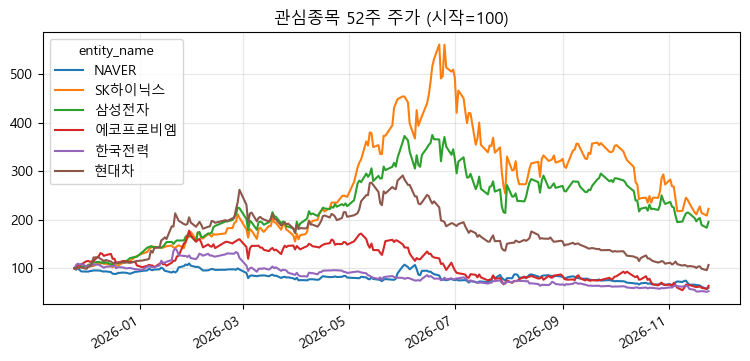

In [12]:
w = px.pivot_table(index="date", columns="entity_name", values="close")
ax = (w / w.iloc[0] * 100).plot(figsize=(9, 4), title="관심종목 52주 주가 (시작=100)")
ax.grid(alpha=.3); ax.set_xlabel(""); plt.show()

## 결과 읽는 법과 한계
- 목록은 **현재 상장 종목 기준**입니다. 과거 시점의 상장사 목록(상장폐지 종목 포함)은 이 함수로 만들 수 없습니다.
- `industry_name`은 통계청 표준산업분류(KSIC)입니다. 거래소 업종·WICS와 다릅니다.
- 식별번호(NICE·사업자·법인)는 보통주와 우선주가 같습니다. 문서의 회사와 맞출 때는 보통주 목록을 쓰세요(→ 2-13).